# NARPS Hypothesis 1: gain effect in vmPFC

**Question.** In the 54-person equal-indifference group, do participant gain-effect estimates show a positive group mean, especially in vmPFC?

**Hypothesis.** Positive gain effect. Primary inference is a one-sided whole-brain maximum-statistic sign-flip test (voxelwise FWE α = .05). vmPFC is operationalized independently as a 10-mm sphere centered at MNI (0, 40, −10) mm; it is shown for localization and summarized descriptively. The ROI does not replace whole-brain correction.

The fixed inputs are AO86 participant contrast parameter estimates from four runs per person. The gain modulator was mean-centered and variance-normalized upstream, so coefficients are not per-currency effects. See `../input/upstream-methods.md` and `../report.md` for full interpretation and limitations.

## Reproducibility

The analysis uses 54 checksum-verified maps, a fixed random seed, and 9,999 random sign flips. The one-sample model gives each participant equal weight because participant variance maps were not supplied. The common analysis mask includes voxels nonzero in all 54 maps.

Run the complete pipeline from the repository root with the prepared Python environment:

```bash
python analysis/run_analysis.py
```

This writes maps, summary tables, and figures under `results/` and `figures/`.

In [1]:
from pathlib import Path
import json
from IPython.display import display, Image

ROOT = Path.cwd()
if not (ROOT / "input").exists():
    ROOT = ROOT.parent
summary = json.loads((ROOT / "results/summary.json").read_text())
display(summary)


{'n_participants': 54,
 'n_excluded': 0,
 'analysis_mask_voxels': 198029,
 'mask_definition': 'nonzero in all 54 maps',
 'coverage_min_in_mask': 1.0,
 'coverage_median_in_mask': 1.0,
 'n_perm': 9999,
 'seed': 20261016,
 'direction': 'positive one-sample group mean',
 'fwe_alpha': 0.05,
 'n_fwe_significant_voxels': 24,
 'max_t': 6.617173246302241,
 'max_t_mni_mm': [-26.0, -102.0, -3.599997043609619],
 'max_t_p_uncorrected': 9.311564027968496e-09,
 'max_t_p_fwe': 0.0006,
 'n_fwe_voxels_overlapping_vmPFC_sphere': 0,
 'roi_center_mni_mm': [0.0, 40.0, -10.0],
 'roi_radius_mm': 10.0,
 'roi_n_voxels': 428,
 'roi_mean_cope': -0.006060326471924782,
 'roi_sd_between_subjects': 0.10310947149991989,
 'roi_ci95_mean_cope': [-0.034203794603008736, 0.022083141659159176],
 'mean_age': 26.055555555555557,
 'sd_age': 3.0493838948818466,
 'gender_counts': {'F': 30, 'M': 24},
 'mean_map_nonzero_voxels': 224257.09259259258,
 'mean_vmPFC_value': -0.006060326471924782}

## Primary group result

A positive whole-brain result supports the hypothesis only if a corrected voxel lies within the vmPFC sphere. Corrected signal elsewhere does not answer the anatomical hypothesis.

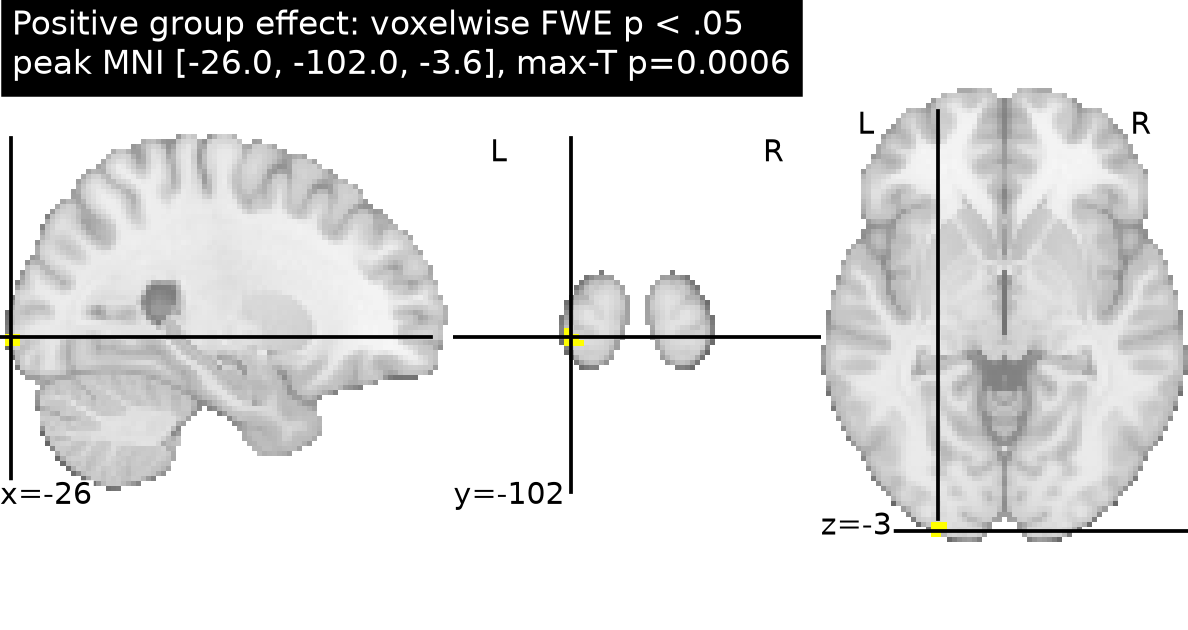

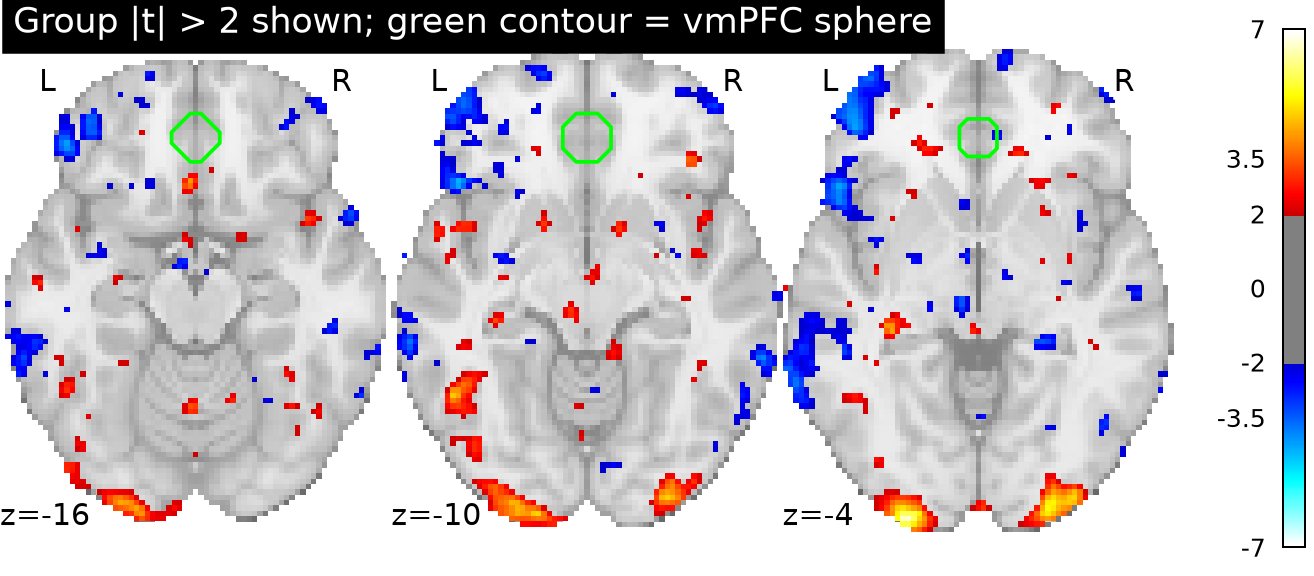

In [2]:
display(Image(filename=str(ROOT / "figures/whole_brain_fwe.png")))
display(Image(filename=str(ROOT / "figures/vmPFC_unthresholded.png")))


## vmPFC participant estimates

The plot shows the mean participant effect and a conventional t-based 95% confidence interval for the ROI average. The estimate scale is the upstream normalized-modulator contrast scale, not currency units.

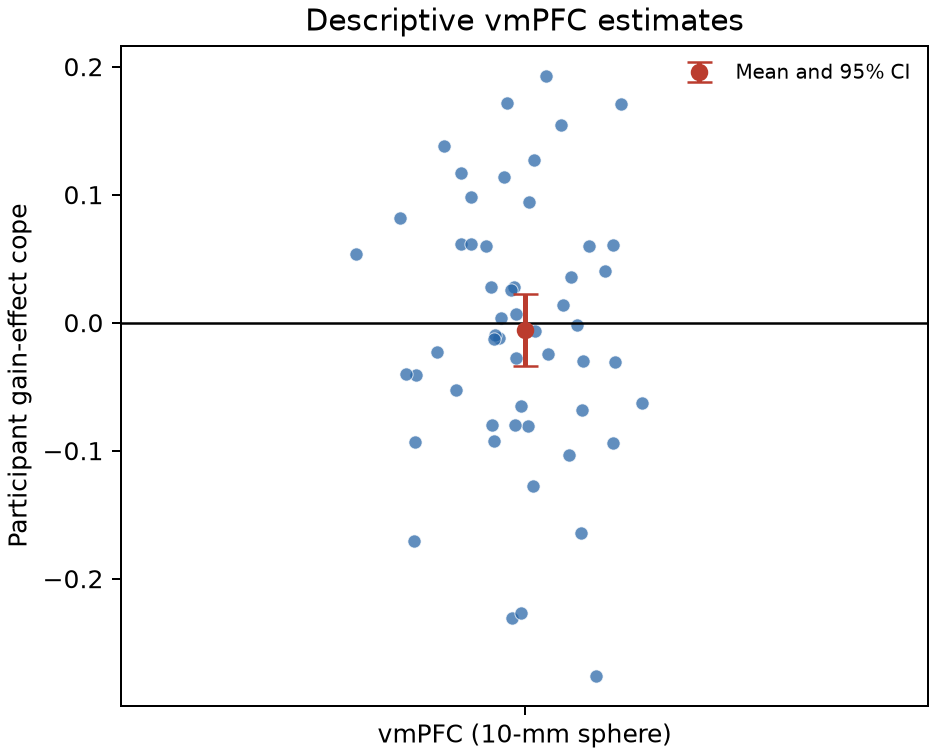

In [3]:
display(Image(filename=str(ROOT / "figures/vmPFC_participant_values.png")))


## Results and interpretation

Read `report.md` for the concise scientific report, including the corrected result, uncertainty, quality checks, exclusions, and limits. `results/summary.json`, `results/fwe_clusters.csv`, and `results/map_qc.csv` contain supporting values. A non-significant vmPFC result would mean that this analysis did not establish the predicted increase; it would not establish no effect.